# 02 – Preprocessing und Datenqualität

Dieses Notebook zeigt, wie die Raw-Snapshots in einen konsistenten Curated Layer überführt werden. Im Mittelpunkt stehen Datumssemantik, Duplikate, fehlende Werte und plausible OHLC-Kurse.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.config import RAW_PRICE_DIR, TICKERS
from src.preprocessing import clean_price_data, find_latest_raw_file

pd.set_option('display.max_columns', 20)
plt.style.use('seaborn-v0_8-whitegrid')

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\sheo1\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


## Qualitätsvergleich vor und nach der Bereinigung

Die Handelstage werden als lokale Börsenkalendertage interpretiert. Dadurch werden deutsche Mitternachtswerte nicht mehr durch eine UTC-Konvertierung auf den Vortag verschoben.

In [2]:
quality_rows = []
clean_frames = []

for ticker in TICKERS:
    raw_path = find_latest_raw_file(RAW_PRICE_DIR, ticker, 'csv')
    raw = pd.read_csv(raw_path)
    date_column = 'Date' if 'Date' in raw.columns else 'Datetime'
    raw_dates = pd.to_datetime(raw[date_column].astype(str).str[:10], errors='coerce')
    clean = clean_price_data(ticker)
    clean_frames.append(clean)
    clean_dates = pd.to_datetime(clean['trade_date'])
    quality_rows.append({
        'ticker': ticker,
        'raw_rows': len(raw),
        'clean_rows': len(clean),
        'removed_rows': len(raw) - len(clean),
        'raw_duplicate_dates': int(raw_dates.duplicated().sum()),
        'clean_duplicate_dates': int(clean_dates.duplicated().sum()),
        'missing_close_after': int(clean['close_price'].isna().sum()),
        'weekend_dates_after': int((clean_dates.dt.dayofweek >= 5).sum()),
    })

clean_prices = pd.concat(clean_frames, ignore_index=True)
quality_df = pd.DataFrame(quality_rows)
quality_df

,ticker,raw_rows,clean_rows,removed_rows,raw_duplicate_dates,clean_duplicate_dates,missing_close_after,weekend_dates_after
0,AAPL,1254,1254,0,0,0,0,0
1,MSFT,1254,1254,0,0,0,0,0
2,NVDA,1254,1254,0,0,0,0,0
3,SAP.DE,1275,1275,0,0,0,0,0
4,ALV.DE,1275,1275,0,0,0,0,0


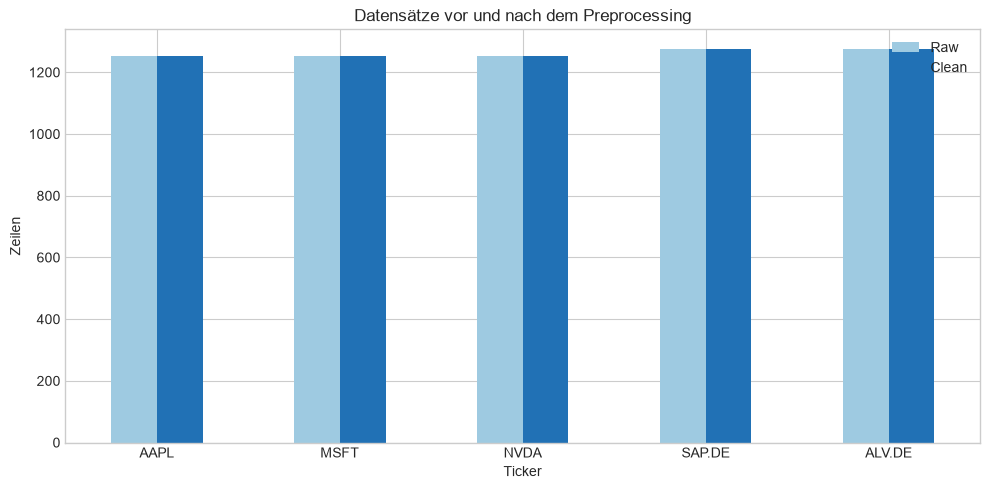

In [3]:
ax = quality_df.set_index('ticker')[['raw_rows', 'clean_rows']].plot(
    kind='bar', figsize=(10, 5), color=['#9ecae1', '#2171b5']
)
ax.set(title='Datensätze vor und nach dem Preprocessing', xlabel='Ticker', ylabel='Zeilen')
ax.legend(['Raw', 'Clean'])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Einheitliches Schema und Plausibilitätschecks

Alle Ticker besitzen anschließend dieselben Spalten und Datentypen. Die folgenden Prüfungen müssen für einen erfolgreichen Lauf alle `True` ergeben.

In [4]:
price_columns = ['open_price', 'high_price', 'low_price', 'close_price']
checks = pd.Series({
    'Keine Duplikate Ticker/Datum': not clean_prices.duplicated(['ticker', 'trade_date']).any(),
    'Keine fehlenden Kernpreise': not clean_prices[price_columns].isna().any().any(),
    'Alle Preise positiv': clean_prices[price_columns].gt(0).all().all(),
    'High ist Tagesmaximum': clean_prices['high_price'].ge(clean_prices[price_columns].max(axis=1)).all(),
    'Low ist Tagesminimum': clean_prices['low_price'].le(clean_prices[price_columns].min(axis=1)).all(),
    'Keine Wochenenddaten': (pd.to_datetime(clean_prices['trade_date']).dt.dayofweek < 5).all(),
}, name='bestanden')
checks.to_frame()

,bestanden
Keine Duplikate Ticker/Datum,True
Keine fehlenden Kernpreise,True
Alle Preise positiv,True
High ist Tagesmaximum,True
Low ist Tagesminimum,True
Keine Wochenenddaten,True


In [5]:
clean_prices.sort_values(['trade_date', 'ticker']).tail(10)

,ticker,trade_date,open_price,high_price,low_price,close_price,volume,dividends,stock_splits
1252,AAPL,2026-08-24,311.470001,313.359985,309.970001,310.339996,34673600,0.0,0.0
6310,ALV.DE,2026-08-24,441.399994,445.500000,441.299988,445.399994,297201,0.0,0.0
2506,MSFT,2026-08-24,483.209991,490.609985,481.859985,487.309998,17230800,0.0,0.0
3760,NVDA,2026-08-24,215.529999,215.589996,207.250000,208.479996,135187300,0.0,0.0
5035,SAP.DE,2026-08-24,186.860001,188.160004,185.520004,187.199997,1540364,0.0,0.0
1253,AAPL,2026-08-25,310.934998,313.579987,308.209991,309.899994,25666176,0.0,0.0
6311,ALV.DE,2026-08-25,447.899994,451.399994,446.700012,450.000000,424756,0.0,0.0
2507,MSFT,2026-08-25,485.565002,492.434998,484.299988,491.709991,19144017,0.0,0.0
3761,NVDA,2026-08-25,211.024994,214.729095,210.110001,213.050003,120441439,0.0,0.0
5036,SAP.DE,2026-08-25,186.399994,187.619995,182.740005,185.460007,1665583,0.0,0.0


## Ergebnis

Das Preprocessing liefert eine eindeutige Ticker-Datum-Kombination, valide OHLC-Werte und korrekte Börsenkalendertage. Dieser Curated Layer ist damit die verlässliche Quelle für Feature Engineering und PostgreSQL.